# 02 - Razvoj rešenja: od očišćenih podataka do finalnog modela

Ova sveska prolazi kroz ceo tok posle EDA, koristeći **iste funkcije iz `src/`** koje
pokreću i skripte (ništa se ne radi "ručno" samo u svesci):

1. čišćenje (`src/data_cleaning.py`) i inženjering karakteristika (`src/feature_engineering.py`)
2. pretprocesiranje i fiksna podela (`src/data_preprocessing.py`)
3. poređenje modela - ortodoksni sklearn + tri neortodoksna (`src/model_comparison.py`, `src/baselines.py`)
4. evaluacija finalnog modela i tumačenje (`src/model_evaluation.py`)
5. predikcija za automobil iz teksta zadatka (`src/predict.py`)

> Teške stvari (random forest, genetsko programiranje, CV) su već izračunate skriptama i
> učitavaju se iz `reports/`; ovde se brzo treniraju samo laki modeli da se vidi tok.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config
from src.data_cleaning import load_raw, clean_data
from src.feature_engineering import add_features
from src.data_preprocessing import build_preprocessor, get_X_y, split_data, ALL_FEATURES, NUMERIC_FEATURES, ONEHOT_FEATURES, TARGET_ENCODED_FEATURES
from src.model_comparison import regression_metrics, sklearn_pipeline
from src.baselines import GroupMedianRegressor, FormulaRegressor
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

## 1. Čišćenje i inženjering karakteristika

Izveštaj ispod je isti onaj koji štampa `python src/data_cleaning.py`.

In [2]:
df_raw = load_raw()
df_clean, report = clean_data(df_raw)
pd.Series({k: v for k, v in report.items() if not isinstance(v, dict)}, name="broj").to_frame()

,broj
rows_raw,56244
duplicates_removed,87
condition_for_parts,454
make_eksklyuziv,55
year_out_of_range,244
price_below_min,235
mileage_set_nan_too_high,357
mileage_set_nan_placeholder,673
mileage_set_nan_too_low,2332
volume_typo_fixed,87


In [3]:
df_feat = add_features(df_clean)
df_feat[["make", "model", "year", "car_age", "mileage_km", "mileage_per_year", "brand_model", "priceUSD"]].sample(8, random_state=1)

,make,model,year,car_age,mileage_km,mileage_per_year,brand_model,priceUSD
10145,citroen,c4-grand-picasso,2010,9,229000.0,25444.444444,citroen_c4-grand-picasso,8000
26506,mercedes-benz,gle,2017,2,124000.0,62000.000000,mercedes-benz_gle,40000
43961,ssangyong,actyon,2012,7,NaN,NaN,ssangyong_actyon,10200
26930,mercedes-benz,r-klass,2007,12,183000.0,15250.000000,mercedes-benz_r-klass,11500
281,alfa-romeo,166,1999,20,250000.0,12500.000000,alfa-romeo_166,2500
37949,peugeot,partner,2012,7,145000.0,20714.285714,peugeot_partner,7850
46873,toyota,yaris,2008,11,189000.0,17181.818182,toyota_yaris,6450
51701,volkswagen,polo,2001,18,240000.0,13333.333333,volkswagen_polo,2000


## 2. Pretprocesiranje i podela

Jedan `ColumnTransformer` za sve modele: imputer + skaler za numeričke, OneHot za marke i
male kategorije, TargetEncoder za `brand_model`. Podela 80/20 sa `random_state=42` je ista
koju koriste sve skripte (`data/processed/train.csv`, `test.csv`).

In [4]:
train_df, test_df = split_data(df_feat)
X_train, y_train = get_X_y(train_df); X_test, y_test = get_X_y(test_df)
pre = build_preprocessor().fit(X_train, np.log1p(y_train))
print("train:", X_train.shape[0], "| test:", X_test.shape[0])
print("numeričke:", NUMERIC_FEATURES)
print("onehot:", ONEHOT_FEATURES)
print("target encoding:", TARGET_ENCODED_FEATURES)
print("kolona posle transformacije:", pre.transform(X_train).shape[1])

train: 44135 | test: 11034
numeričke: ['car_age', 'mileage_km', 'volume_cm3', 'mileage_per_year']
onehot: ['make', 'condition', 'fuel_type', 'color', 'transmission', 'drive_unit', 'segment']
target encoding: ['brand_model']
kolona posle transformacije: 107


## 3. Modeli - brzi pregled toka na dva laka modela

Dva brza modela da se vidi mehanika; kompletno poređenje (9 modela) je u sledećem odeljku.
`sklearn_pipeline(model, log_target=True)` = preprocessor + model, umotano u
`TransformedTargetRegressor` koji uči `log1p(cena)` i vraća dolare.

In [5]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

quick = {
    "GroupMedian lookup (bez ML)": GroupMedianRegressor(),
    "Ridge (log)": sklearn_pipeline(Ridge(alpha=1.0), log_target=True),
    "HistGradientBoosting (log, 300 iter)": sklearn_pipeline(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42), log_target=True),
    "Formula: base + 4 člana": FormulaRegressor(max_terms=4),
}
rows = []
for name, model in quick.items():
    model.fit(X_train, y_train)
    rows.append({"model": name, **regression_metrics(y_test, model.predict(X_test))})
pd.DataFrame(rows).round(3)

,model,MAE,MSE,RMSE,R2,MedAPE
0,GroupMedian lookup (bez ML),1180.707,1.028260e+07,3206.649,0.836,0.122
1,Ridge (log),1500.172,1.167973e+07,3417.562,0.814,0.166
2,"HistGradientBoosting (log, 300 iter)",1105.106,6.204774e+06,2490.938,0.901,0.128
3,Formula: base + 4 člana,1277.047,9.211793e+06,3035.093,0.853,0.143


In [6]:
print(quick["Formula: base + 4 člana"].formula_)

log(price) = base(brand_model) +9.850 -0.1002*age +0.1862*log(liters+1) -0.6643*damaged -0.0013*age*km


## 4. Kompletno poređenje (iz `python src/model_comparison.py`)

Svi modeli su trenirani na istom train skupu i mereni na istom test skupu.
Crveno su neortodoksni pristupi: lookup bez ML-a, formula, genetsko programiranje.

In [7]:
comparison = pd.read_csv("../reports/model_comparison.csv")
comparison.round(3)

,model,target,MAE,MSE,RMSE,R2,MedAPE,train_time_s
0,RandomForest,log,1000.222,5.404362e+06,2324.728,0.914,0.116,26.507
1,HistGradientBoosting,log,1022.855,5.375984e+06,2318.617,0.914,0.119,7.102
2,HistGradientBoosting (raw $),raw,1050.856,4.948481e+06,2224.518,0.921,0.122,5.089
3,GroupMedian lookup (bez ML),raw,1180.707,1.028260e+07,3206.649,0.836,0.122,0.043
4,DecisionTree,log,1260.595,8.406585e+06,2899.411,0.866,0.139,0.489
5,Formula: base + 4 člana,log,1277.047,9.211793e+06,3035.093,0.853,0.143,0.056
6,Symbolic GP (gplearn),log,1317.593,1.111504e+07,3333.923,0.823,0.143,151.212
7,Ridge,log,1500.172,1.167973e+07,3417.562,0.814,0.166,0.274
8,LinearRegression,raw,2452.613,2.028638e+07,4504.041,0.676,0.299,0.503


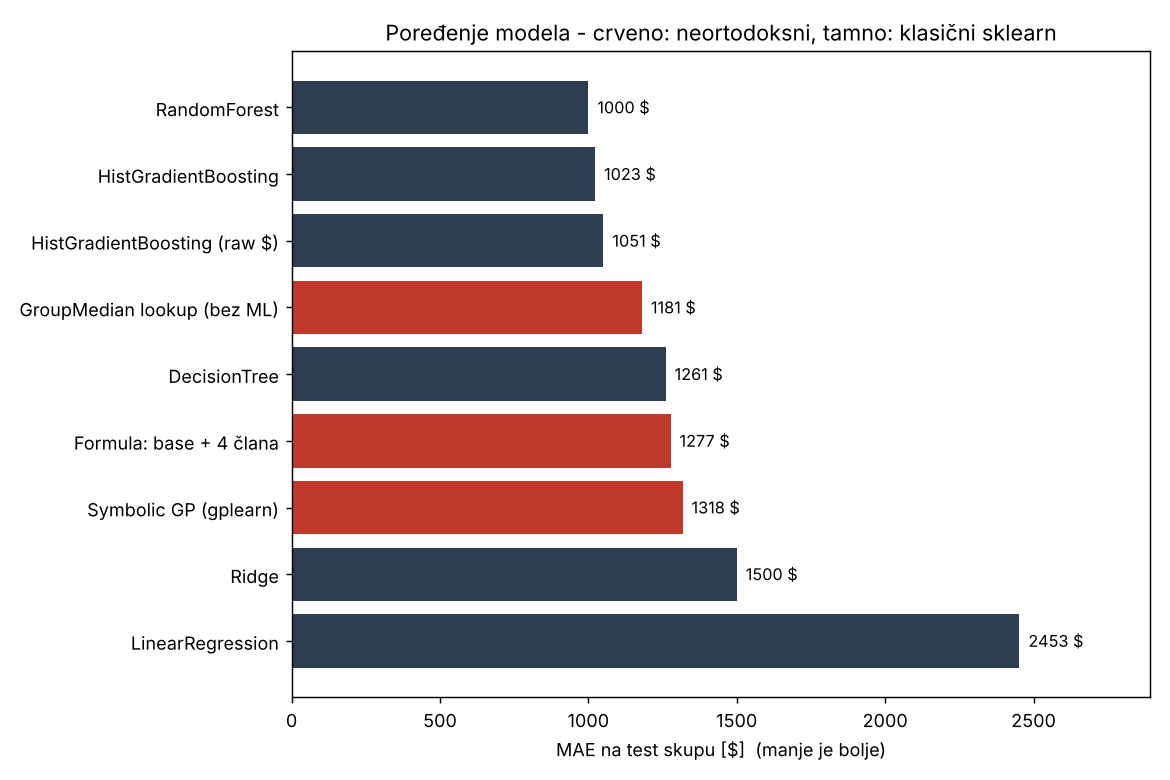

In [8]:
display(Image("../reports/figures/model_comparison_mae.png"))

In [9]:
print(open("../reports/formulas.txt", encoding="utf-8").read())

Formula: base + 4 člana:
log(price) = base(brand_model) +9.850 -0.1002*age +0.1862*log(liters+1) -0.6643*damaged -0.0013*age*km

Symbolic GP (gplearn):
log(price) = base(brand_model) + sub(div(mul(liters, -1.456), mul(liters, -0.136)), add(div(0.242, sub(div(0.242, div(age, 1.309)), mul(age, -0.122))), add(damaged, sub(div(-0.032, -0.147), mul(age, -0.122)))))


In [10]:
cv = pd.read_csv("../reports/cv_results.csv")
cv.round(1)

,model,cv_MAE_mean,cv_MAE_std,folds
0,RandomForest,1040.1,10.7,1054 | 1031 | 1033 | 1030 | 1053
1,HistGradientBoosting,1049.6,20.5,1072 | 1045 | 1029 | 1027 | 1075
2,HistGradientBoosting (raw $),1080.0,20.1,1090 | 1099 | 1053 | 1058 | 1100


### Čitanje tabele

- **Lookup bez ML-a (medijana istih vozila) pobeđuje linearne modele i stablo.** Ako sistem
  ne pobedi tabelu medijana, nema razloga da postoji - to je prava nulta tačka, ne prosek.
- **Log-cilj vredi**: isti boosting u sirovoj skali ima lošiji MAE, bolji RMSE - u sirovoj
  skali model "juri" skupe aute na račun jeftinih, kojih je 90 %.
- **Formula sa 4 člana** je čitljiva i blizu lookup-a; **genetsko programiranje** daje
  upotrebljivu, ali rogobatnu formulu i to samo uz pažljivo podešavanje (vidi README).
- **Ensemble modeli na stablima (RandomForest, HistGradientBoosting)** su najbolji po svim
  metrikama; razlika između njih dvojice je unutar šuma CV foldova.

## 5. Finalni model i evaluacija (iz `python src/model_evaluation.py`)

In [11]:
metrics = json.load(open("../reports/evaluation_metrics.json", encoding="utf-8"))
print("model:", metrics["model"], "| test redova:", metrics["test_rows"])
pd.Series(metrics["metrics"]).round(3).to_frame("vrednost")

model: HistGradientBoosting | test redova: 11034


,vrednost
MAE,1022.855
MSE,5375983.782
RMSE,2318.617
R2,0.914
MedAPE,0.119


In [12]:
pd.read_csv("../reports/evaluation_examples.csv")

,make,model,year,mileage_km,stvarna_cena,predvidjena_cena,greska,greska_%
0,toyota,corolla-verso,2005,350000.0,7250,7149.0,101.0,1.4
1,skoda,octavia,2009,159000.0,7800,7260.0,540.0,6.9
2,lada-vaz,xray,2019,2500.0,11450,11964.0,514.0,4.5
3,volkswagen,golf,1996,120000.0,808,1577.0,769.0,95.2
4,infiniti,fx,2011,120000.0,19750,18882.0,868.0,4.4
5,nissan,primera,1997,300000.0,1188,1626.0,438.0,36.9
6,renault,megane,1998,380000.0,2000,1482.0,518.0,25.9
7,toyota,corolla,1996,271000.0,1590,1274.0,316.0,19.9
8,volkswagen,passat,2008,142000.0,8300,8077.0,223.0,2.7
9,volkswagen,golf-plus,2011,130600.0,7700,8171.0,471.0,6.1


In [13]:
pd.read_csv("../reports/evaluation_by_price_band.csv").round(3)

,cenovni_razred,n,MAE,MedAPE
0,< 3.000 $,3259,440.117,0.227
1,3.000-7.000 $,3433,681.274,0.108
2,7.000-15.000 $,3250,1141.232,0.084
3,15.000-30.000 $,905,2520.518,0.101
4,> 30.000 $,187,8144.128,0.118


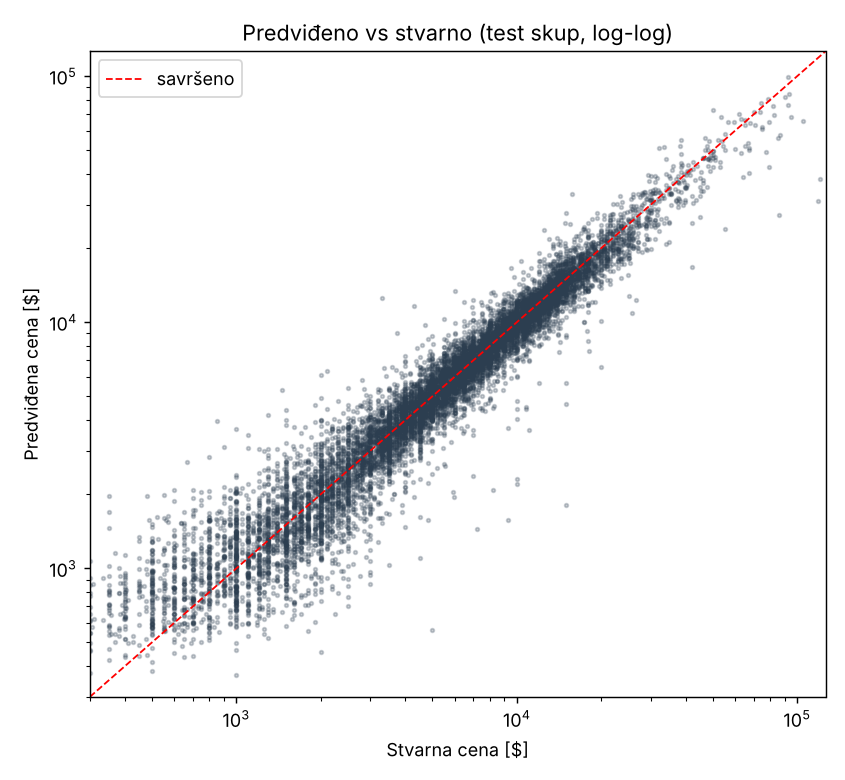

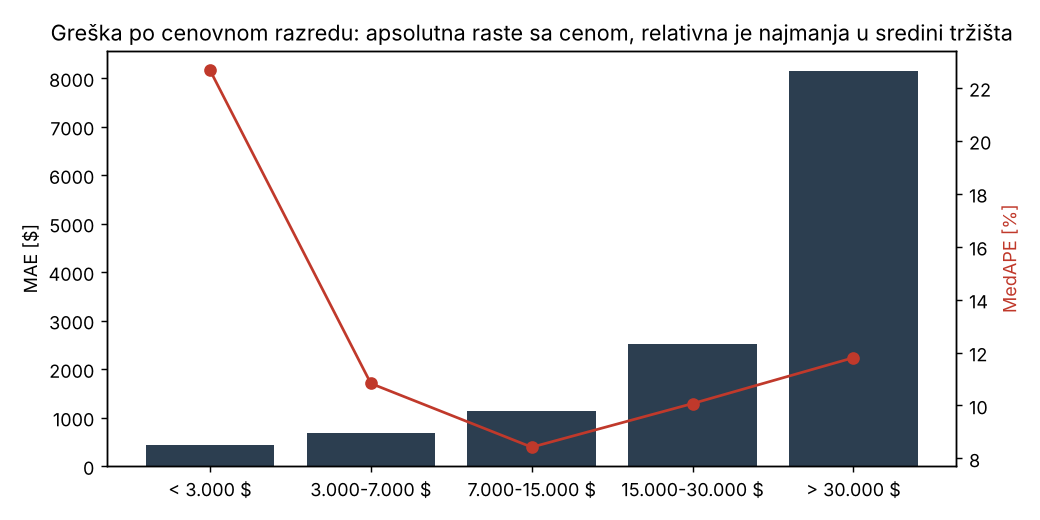

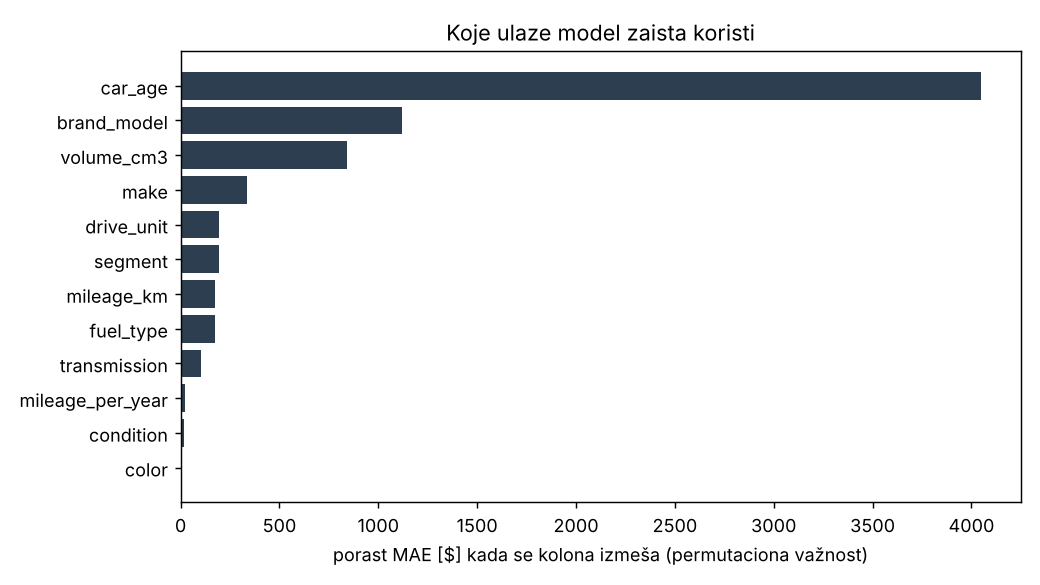

In [14]:
display(Image("../reports/figures/pred_vs_actual.png"))
display(Image("../reports/figures/mae_by_price_band.png"))
display(Image("../reports/figures/feature_importance.png"))

In [15]:
pd.read_csv("../reports/evaluation_worst.csv")

,make,model,year,condition,mileage_km,volume_cm3,stvarna_cena,predvidjena_cena,greska
0,land-rover,range-rover,2018,with mileage,23301.0,2000.0,118000,30950.0,87050.0
1,bentley,mulsanne,2011,with mileage,178471.0,6800.0,120000,38232.0,81768.0
2,tesla,model-3,2019,with mileage,50.0,0.0,86353,27126.0,59227.0
3,mercedes-benz,s-klass,2017,with mileage,8500.0,3000.0,105000,65434.0,39566.0
4,mercedes-benz,e-klass,2017,with mileage,140000.0,3000.0,79500,42688.0,36812.0
5,land-rover,defender,2014,with mileage,39000.0,2200.0,55000,23886.0,31114.0
6,bmw,7-seriya,2018,with mileage,37000.0,3000.0,87000,57787.0,29213.0
7,bmw,7-seriya,2018,with mileage,47000.0,2993.0,85000,56218.0,28782.0


### Tumačenje

MAE od ~1.000 $ na medijani cene od ~5.500 $ znači da je tipična greška oko 18 % cene,
ali raspodela greške nije uniformna: na jeftinim autima (< 3.000 $) apsolutna greška je
nekoliko stotina dolara, a na skupim (> 30.000 $) nekoliko hiljada - relativno gledano,
model je **najbolji u sredini tržišta** gde ima najviše podataka. Najveći promašaji su
retki i neobični automobili (malo primeraka tog modela, ekstremne godine/kilometraže) -
tu ni iskusan procenitelj ne bi bio siguran, i zato platforma dobija i interval "od-do".

## 6. Primer iz zadatka: Volkswagen Golf 2014, dizel 1.6, 180.000 km

In [16]:
from src.predict import predict_price
car = {"make": "volkswagen", "model": "golf", "year": 2014, "condition": "with mileage",
       "mileage_km": 180000, "fuel_type": "diesel", "volume_cm3": 1600, "color": "black",
       "transmission": "mechanics", "drive_unit": "front-wheel drive", "segment": "C"}
result = predict_price(car)
print(f"Procena: {result['price_usd']:,.0f} $")
print(f"Interval 10-90 %: {result['interval_10_90'][0]:,.0f} - {result['interval_10_90'][1]:,.0f} $")
print(f"Formula-model: {result['formula_price_usd']:,.0f} $")

Procena: 12,159 $
Interval 10-90 %: 10,843 - 13,196 $
Formula-model: 13,498 $


In [17]:
# Koliko zaista koštaju slični golfovi u podacima (2013-2015, dizel)?
similar = df_feat[(df_feat.make == "volkswagen") & (df_feat.model == "golf") & df_feat.year.between(2013, 2015) & (df_feat.fuel_type == "diesel")]
print(len(similar), "oglasa"); similar["priceUSD"].describe().round(0)

29 oglasa


count       29.0
mean     12449.0
std       1220.0
min      10500.0
25%      11650.0
50%      12200.0
75%      12999.0
max      15514.0
Name: priceUSD, dtype: float64